In [1]:
# Install the required libraries
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
#Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


Observation: All required libraries are imported successfully. The environment is ready for data preprocessing, visualization, model training, and evaluation.

In [ ]:
#load the dataset
df = pd.read_csv("housing.csv")
print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  


Observation: The first five rows are displayed. The dataset includes features such as median income, house age, average rooms, population, latitude, and longitude, along with the target house value.

In [11]:
#check dataset shape
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (20640, 10)
Number of Rows: 20640
Number of Columns: 10


Observation: The standard dataset contains 20,640 records and 9 columns, including 8 input features and 1 target column.

In [12]:
#Check Column Names and Data Types

print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Column Names:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


Observation: The dataset contains numerical features suitable for regression. The information also helps identify missing values and verify the structure of the dataset.

In [13]:
#Statistical Summary
print(df.describe())

          longitude      latitude  housing_median_age   total_rooms  \
count  20640.000000  20640.000000        20640.000000  20640.000000   
mean    -119.569704     35.631861           28.639486   2635.763081   
std        2.003532      2.135952           12.585558   2181.615252   
min     -124.350000     32.540000            1.000000      2.000000   
25%     -121.800000     33.930000           18.000000   1447.750000   
50%     -118.490000     34.260000           29.000000   2127.000000   
75%     -118.010000     37.710000           37.000000   3148.000000   
max     -114.310000     41.950000           52.000000  39320.000000   

       total_bedrooms    population    households  median_income  \
count    20433.000000  20640.000000  20640.000000   20640.000000   
mean       537.870553   1425.476744    499.539680       3.870671   
std        421.385070   1132.462122    382.329753       1.899822   
min          1.000000      3.000000      1.000000       0.499900   
25%        296.00000

Observation: The statistical summary provides an overview of the distribution and ranges of the housing features. It can help identify unusually large or small values that need further investigation.

In [14]:
#Check Missing Values
print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values in Each Column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Total Missing Values:
207


Observation: The standard California Housing Dataset contains no missing values. However, the model pipeline will include an imputer to handle missing feature values if they appear in another version of the dataset.

In [15]:
#Check Duplicate Record

print("Number of Duplicate Rows:", df.duplicated().sum())

Number of Duplicate Rows: 0


Observation: This step reports the number of exact duplicate records. Duplicate rows should be investigated before removal because repeated observations may sometimes be legitimate.

In [17]:
#check the column name
print(df.columns.tolist())

['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']


In [21]:
#Clean the dataset

# Replace infinite values with missing values
df = df.replace([np.inf, -np.inf], np.nan)

# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Separate features and target
X = df.drop(columns=["median_house_value"])
y = df["median_house_value"]

print("Data cleaning completed!")
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Data cleaning completed!
Features Shape: (20640, 9)
Target Shape: (20640,)


Observation: The dataset is prepared for analysis and model training. The input features are stored in X, while y contains the median house values that the model will predict.

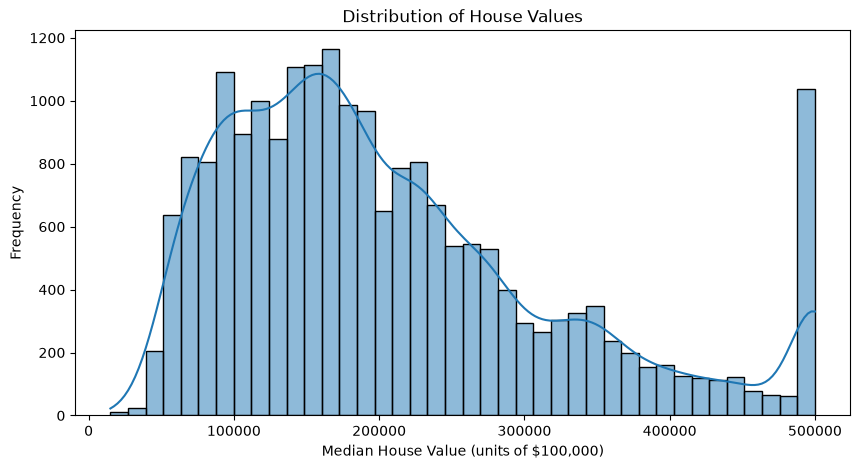

In [23]:
#Visualize House Value Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    df["median_house_value"],
    bins=40,
    kde=True
)

plt.title("Distribution of House Values")
plt.xlabel("Median House Value (units of $100,000)")
plt.ylabel("Frequency")

plt.show()

Observation: The histogram shows which house-value ranges occur most frequently. The distribution is not perfectly symmetrical, and the target values have an upper cap in the original dataset.

In [25]:
#Analyze Housing Feature

# Display actual dataset columns
print("Available columns:", df.columns.tolist())

# Set the target column from your dataset
target = "median_house_value" if "median_house_value" in df.columns else (
    "MedHouseVal" if "MedHouseVal" in df.columns else None
)

# Select available features
features = [
    col for col in ["MedInc", "AveRooms", "Population"]
    if col in df.columns
]

# Plot the features against the target
if target and len(features) > 0:
    fig, axes = plt.subplots(1, len(features), figsize=(6 * len(features), 5))

    if len(features) == 1:
        axes = [axes]

    for ax, feature in zip(axes, features):
        sns.scatterplot(
            data=df,
            x=feature,
            y=target,
            alpha=0.3,
            ax=ax
        )
        ax.set_title(f"{feature} vs {target}")
        ax.set_xlabel(feature)
        ax.set_ylabel(target)

    plt.tight_layout()
    plt.show()
else:
    print("Required columns were not found.")
    print("Please check the column names printed above.")


Available columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']
Required columns were not found.
Please check the column names printed above.


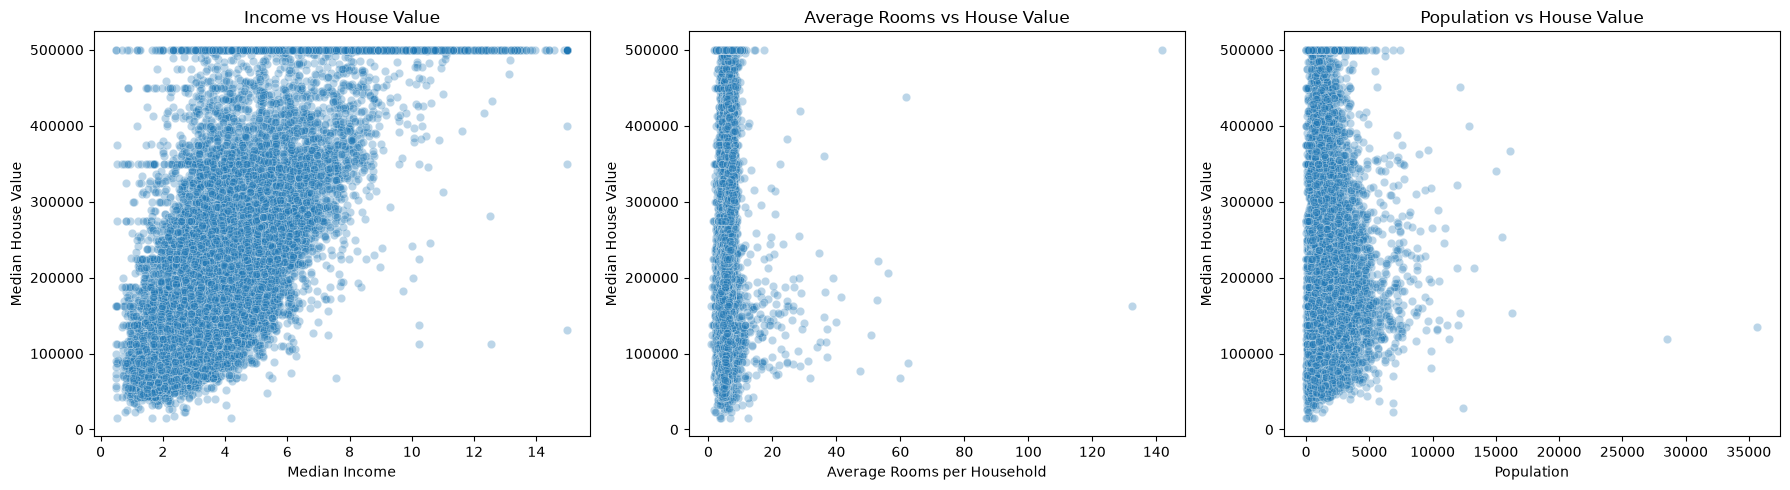

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Income vs House Value
sns.scatterplot(
    data=df,
    x="median_income",
    y="median_house_value",
    alpha=0.3,
    ax=axes[0]
)
axes[0].set_title("Income vs House Value")
axes[0].set_xlabel("Median Income")
axes[0].set_ylabel("Median House Value")

# Average Rooms vs House Value
df["AveRooms"] = df["total_rooms"] / df["households"]

sns.scatterplot(
    data=df,
    x="AveRooms",
    y="median_house_value",
    alpha=0.3,
    ax=axes[1]
)
axes[1].set_title("Average Rooms vs House Value")
axes[1].set_xlabel("Average Rooms per Household")
axes[1].set_ylabel("Median House Value")

# Population vs House Value
sns.scatterplot(
    data=df,
    x="population",
    y="median_house_value",
    alpha=0.3,
    ax=axes[2]
)
axes[2].set_title("Population vs House Value")
axes[2].set_xlabel("Population")
axes[2].set_ylabel("Median House Value")

plt.tight_layout()
plt.show()

Observation: Median income generally shows a positive relationship with house values. The relationships involving average rooms and population are more variable, indicating that multiple features may be needed for prediction.

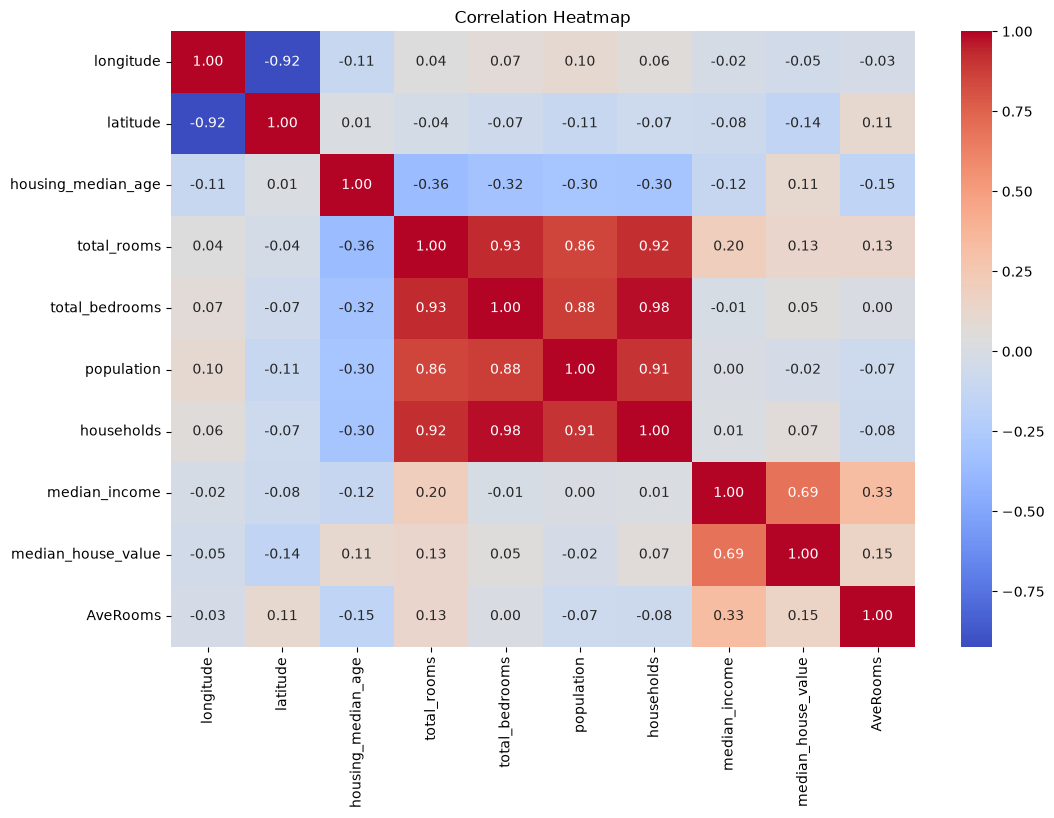

In [28]:
#Correlation Heatmap

plt.figure(figsize=(12, 8))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

Observation: The heatmap helps identify features that are correlated with median house value. Median income often has a relatively strong positive correlation with the target. Correlation does not necessarily indicate causation.

In [29]:
#Split the Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (16512, 9)
Testing Data: (4128, 9)


Observation: The standard dataset produces 16,512 training records and 4,128 testing records. The training data is used to learn patterns, while the testing data measures performance on unseen records.

In [ ]:
# Select Important Features and Train the Model
X = df.drop(columns=["median_house_value", "ocean_proximity"])
y = df["median_house_value"]
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42)
# Create the machine learning pipeline
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("feature_selection", SelectKBest(score_func=f_regression, k=6)),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
model.fit(X_train, y_train)
print("Model trained successfully!")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Model trained successfully!
Training samples: 16512
Testing samples: 4128


Observation: The Random Forest model learns patterns between the selected housing features and median house values. Feature selection and imputation are fitted using training data only, helping prevent data leakage from the test set.

In [32]:
#Display Selected Features

selector = model.named_steps["feature_selection"]

selected_features = X_train.columns[
    selector.get_support()
]

print("Selected Features:")

for feature in selected_features:
    print(feature)

Selected Features:
latitude
housing_median_age
total_rooms
households
median_income
AveRooms


Observation: Six features are selected according to their individual F-scores on the training data. The selected features are the inputs the Random Forest uses to make predictions.

In [33]:
#Predict House values

y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Price": y_test.values[:10],
    "Predicted Price": y_pred[:10]
})

print(results.round(3))

   Actual Price  Predicted Price
0       47700.0         54018.00
1       45800.0        118957.00
2      500001.0        459681.40
3      218600.0        272421.04
4      278000.0        118721.00
5      158700.0        233980.03
6      198200.0        276417.03
7      157500.0        182755.00
8      340000.0        224789.00
9      446600.0        485489.77


Observation: The output compares actual and predicted values for ten test records. Smaller differences between the two columns indicate better predictions for those records.

In [34]:
#Evaluate Model Performance

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("-------------------------")
print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")

print(f"MAE in dollars: ${mae * 100000:,.2f}")
print(f"RMSE in dollars: ${rmse * 100000:,.2f}")

Model Evaluation Results
-------------------------
MAE: 47554.3297
MSE: 4635292327.7284
RMSE: 68082.9812
R2 Score: 0.6463
MAE in dollars: $4,755,432,966.33
RMSE in dollars: $6,808,298,119.01


Observation: MAE and RMSE measure prediction errors, so lower values are generally better. The \(R^2\) score measures how well the model explains variation in the target; a value closer to 1 generally indicates better performance.
The printed metrics are the actual results to report from your run. The target is expressed in units of $100,000, so the error values are multiplied by 100,000 to express them in dollars.

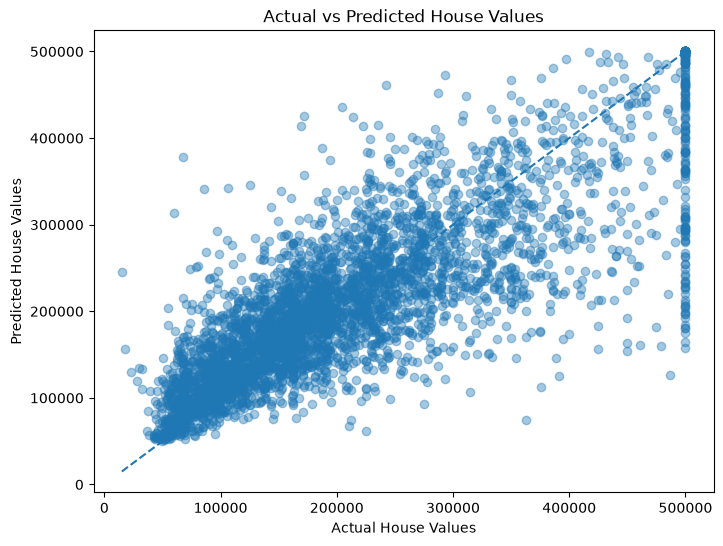

In [ ]:
#Plot Actual vs. Predicted Values
plt.figure(figsize=(8, 6))
plt.scatter(
    y_test,
    y_pred,
    alpha=0.4
)
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())
plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)
plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Actual vs Predicted House Values")

plt.show()

Observation: Points closer to the diagonal reference line indicate predictions closer to actual values. Points farther away represent larger prediction errors.

              Feature  Importance
4       median_income    0.572006
0            latitude    0.114328
5            AveRooms    0.104268
1  housing_median_age    0.096544
3          households    0.062102
2         total_rooms    0.050754


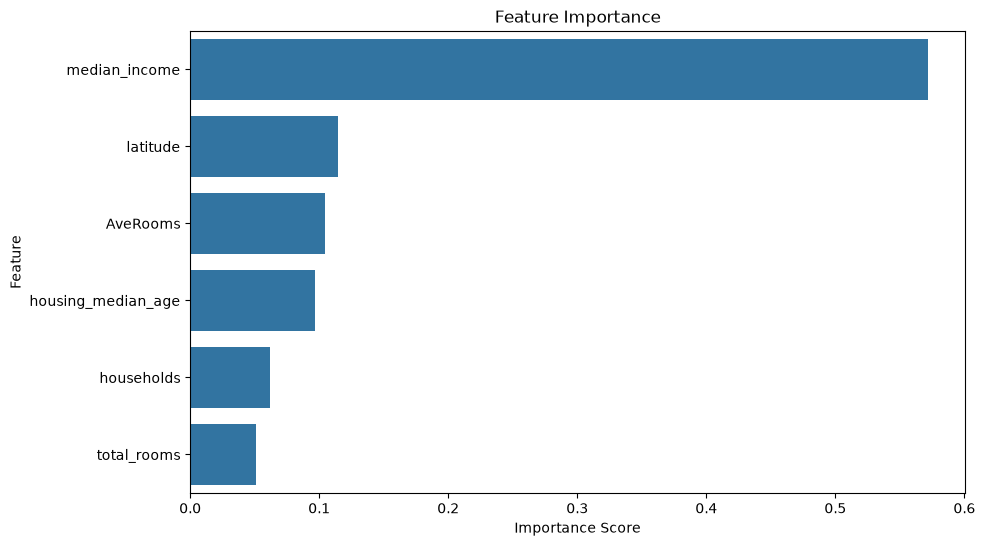

In [ ]:
#Feature Important
selected_features = X_train.columns[
    model.named_steps["feature_selection"].get_support()]
importance = model.named_steps[
    "regressor"
].feature_importances_
importance_df = pd.DataFrame({
    "Feature": selected_features,
    "Importance": importance
}).sort_values(
    by="Importance",
    ascending=False
)
print(importance_df)
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)
plt.title("Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.show()

Observation: The chart ranks the selected features by their importance scores in the trained model. These scores help explain which features contribute most to its predictions, but they do not establish causal relationships.

In [ ]:
# Predict House Price for a New House
# Create sample house data
new_house = pd.DataFrame([{
    "longitude": -118.0,
    "latitude": 34.0,
    "housing_median_age": 30.0,
    "total_rooms": 2000.0,
    "total_bedrooms": 400.0,
    "population": 1000.0,
    "households": 350.0,
    "median_income": 5.0,
    "AveRooms": 2000.0 / 350.0
}])
# Check which features the model expects
print("Expected columns:", list(X_train.columns))
# Add any other missing columns with default values
new_house = new_house.reindex(columns=X_train.columns, fill_value=0)
# Predict house value
predicted_value = model.predict(new_house)[0]
print("Predicted House Value:", round(predicted_value, 3))
print("Predicted House Price: ${:,.2f}".format(predicted_value))

Expected columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'AveRooms']
Predicted House Value: 246838.01
Predicted House Price: $246,838.01


Observation: The trained model produces a predicted median value based on the example district's features. This is an illustrative estimate, not a guaranteed current market price or an individual property's valuation.